# Absorption Imaging Lab

Python companion to the AMO Toolkit page [Absorption Imaging Lab](https://amotoolkit.com/pages/absorption-imaging.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/absorption-imaging.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Photon budget and noise per pixel
Cross section $\sigma(\Delta) = \sigma_0/(1+4\Delta^2/\Gamma^2)$ (cycling transition, low intensity); object-plane pixel = camera pixel / magnification; detected probe photons per pixel $N = (I/\hbar\omega)\,t\,A_\mathrm{pix}\,QE$. An OD measured from an atom and a reference image has shot noise $\sqrt{2/N}$ and read noise $\sqrt2\,\sigma_e/N$; the page calls 3 δOD the minimum detectable OD and converts it to an atom number for a 10 µm cloud.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
hbar, c = 1.054571817e-34, 299792458
SPECIES = {   # λ (m), σ0 (m²), I_sat (W/m²)
    "Rb87": (780.24e-9, 2.907e-13, 16.69), "Cs133": (852.347e-9, 3.469e-13, 11.02), "Li6": (670.977e-9, 2.150e-13, 25.4),
    "Li7": (670.961e-9, 2.149e-13, 25.4), "Na23": (589.158e-9, 1.657e-13, 62.6), "K39": (766.70e-9, 2.807e-13, 17.5),
    "K40": (766.70e-9, 2.807e-13, 17.5),
}

def imaging(sp="Rb87", det_gamma=0.0, s=0.10, t_us=20, pix_um=6.5, M=5.0, QE=0.8, read_e=5):
    lam, s0, Isat = SPECIES[sp]
    sig = s0 / (1 + 4 * det_gamma**2)
    p_obj = pix_um / M; A = (p_obj * 1e-6) ** 2
    N = s * Isat / (hbar * 2 * np.pi * c / lam) * t_us * 1e-6 * A * QE
    shot, read = np.sqrt(2 / N), np.sqrt(2) * read_e / N
    OD_min = 3 * np.hypot(shot, read)
    A_roi = max(np.pi * (10e-6) ** 2, A)
    return dict(sigma_1e13=sig * 1e13, p_obj_um=p_obj, N_ph=N, dOD_shot=shot, dOD_read=read, OD_min=OD_min,
                N_min=OD_min * np.sqrt(A * A_roi) / sig, sat_bias_pct=100 * s / (1 + s))

r = imaging()      # page defaults: Rb-87, resonant, s = 0.1, 20 µs, 6.5 µm pixels, ×5
for k, v in r.items(): print(f"{k:>13} = {v:.4g}")

   sigma_1e13 = 2.907
     p_obj_um = 1.3
         N_ph = 177.3
     dOD_shot = 0.1062
     dOD_read = 0.03989
       OD_min = 0.3404
        N_min = 26.98
 sat_bias_pct = 9.091

## 2. Optical depth and atom number
Beer–Lambert: $I = I_0 e^{-\mathrm{OD}}$, $\mathrm{OD} = n_{2D}\,\sigma$. Atom number $N = (A_\mathrm{pix}/\sigma)\sum_i \mathrm{OD}_i$. At finite intensity, $\mathrm{OD}$ underestimates the column density by about $s/(1+s)$ unless you use the saturation-corrected form $n\sigma = \mathrm{OD} + (I_0-I)/I_\mathrm{sat}$ (Reinaudi et al., Opt. Lett. 32, 3143 (2007)). Below: a synthetic image with shot noise, then the atom count.

peak OD 5.78; counted N = 1.81e+05 (true 2e+05)

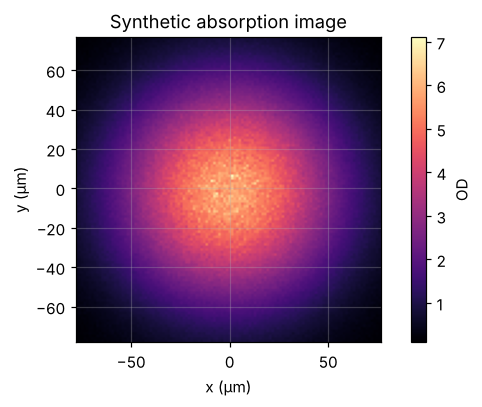

In [2]:
rng = np.random.default_rng(3)
lam, s0, Isat = SPECIES["Rb87"]
N_atoms, sig_cloud = 2e5, 40e-6
pix = 6.5e-6 / 5; n_pix = 120
x = (np.arange(n_pix) - n_pix / 2) * pix; X, Y = np.meshgrid(x, x)
n2d = N_atoms / (2 * np.pi * sig_cloud**2) * np.exp(-(X**2 + Y**2) / (2 * sig_cloud**2))
OD_true = n2d * s0
Nref = r["N_ph"] * 20                       # a brighter probe than the default, so the picture is clean
ref = rng.poisson(Nref, X.shape); img = rng.poisson(Nref * np.exp(-OD_true))
OD = -np.log(np.maximum(img, 1) / ref)
print(f"peak OD {OD_true.max():.2f}; counted N = {pix**2 / s0 * OD.sum():.3g} (true {N_atoms:.3g})")
plt.imshow(OD, extent=[x[0]*1e6, x[-1]*1e6, x[0]*1e6, x[-1]*1e6], cmap="magma"); plt.colorbar(label="OD")
plt.xlabel("x (µm)"); plt.ylabel("y (µm)"); plt.title("Synthetic absorption image")

The count comes out low because the centre of this cloud is optically thick (OD ≈ 6): almost no probe light gets through, the measured OD saturates, and the atoms there are undercounted. Detune the probe, wait for a longer time of flight, or lower N in the cell above until the peak OD is below about 2, and the count recovers.

## 3. Check against the page

In [3]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

DECIMALS = dict(sigma_1e13=2, p_obj_um=2, N_ph=0, dOD_shot=4, dOD_read=4, OD_min=4, N_min=0)
page = dict(sigma_1e13=2.91, p_obj_um=1.30, N_ph=177, dOD_shot=0.1062, dOD_read=0.0399, OD_min=0.3404, N_min=27)
check(r, page)

  sigma_1e13: notebook 2.907        page 2.91       OK
    p_obj_um: notebook 1.3          page 1.3        OK
        N_ph: notebook 177.3        page 177        OK
    dOD_shot: notebook 0.1062       page 0.1062     OK
    dOD_read: notebook 0.03989      page 0.0399     OK
      OD_min: notebook 0.3404       page 0.3404     OK
       N_min: notebook 26.98        page 27         OK
All values match the page.